# 04. 최적 학습 조건 찾기 — 교실 실측 + 인공신경망 + 생성형 AI
1. **교실 실측(7반, 5일):** 하루 중 CO₂가 언제 얼마나 높은지, 창문을 열면 얼마나 빨리 떨어지는지
2. **인공신경망 상태 분류기:** CO₂와 소리 조건을 바꿔 가며 '최적' 확률이 어떻게 변하는지(확률 지도)
3. 1·2의 결과를 생성형 AI에 주고 해석·제안을 받는다(프롬프트 개선 과정은 `docs/prompt_log.md`)

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from common import *

c = pd.read_csv(f"{RAW}/datasci_7ban_co2_main.csv", encoding="utf-8-sig")
c["time"] = pd.to_datetime(c["measured_at"])
wc = [k for k in c.columns if k.startswith("w") and k[1:].isdigit()]
c["win_n"] = (c[wc].fillna(0) > .5).sum(axis=1)          # 열린 창문 개수
med = c["co2"].rolling(7, center=True, min_periods=3).median()
c.loc[(c["co2"] - med).abs() > 300, "co2"] = np.nan          # 순간 튐(측정 오류) 제거 — 02번과 같은 기준
c["co2s"] = c["co2"].rolling(3, min_periods=2).median()
c["hour"] = c["time"].dt.hour + c["time"].dt.minute / 60
day_ok = c["time"].dt.weekday < 5
print(f"교실 측정 {c.co2.notna().sum():,}분 ({c.time.min():%m/%d}~{c.time.max():%m/%d})")

교실 측정 4,270분 (11/02~11/06)


## 1) 하루 중 CO₂ 흐름 (시간대별 평균)
학교 시간표: 오후 수업 → 청소(약 16:00, 창문 열기) → 저녁(18:00~18:50, 교실 빔) → 야간 자율학습(19:00~22:00, 쉬는 시간 20:25~20:40)

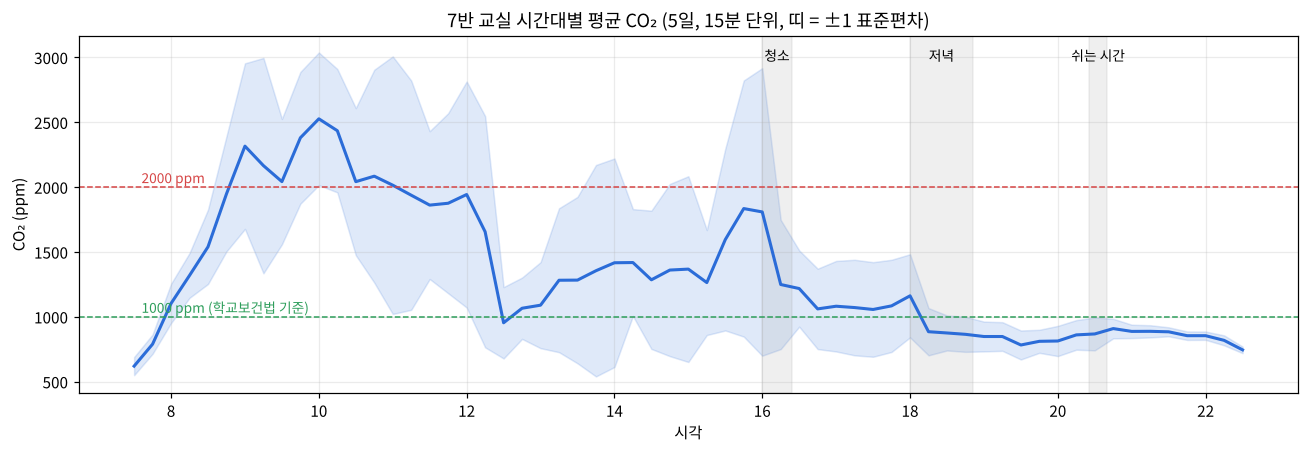

수업·자습 시간(8~22시) 중 CO₂ ≥ 1000 ppm 비율: 52%
수업·자습 시간(8~22시) 중 CO₂ ≥ 1500 ppm 비율: 32%
수업·자습 시간(8~22시) 중 CO₂ ≥ 2000 ppm 비율: 20%
수업·자습 시간(8~22시) 중 CO₂ ≥ 2500 ppm 비율: 11%


In [2]:
prof = c[day_ok].assign(slot=(c["hour"] * 4).round() / 4).groupby("slot")["co2s"].agg(["mean", "std", "count"])
prof = prof[(prof.index >= 7.5) & (prof.index <= 22.5) & (prof["count"] >= 3)]
fig, a = plt.subplots(figsize=(12, 4.2))
a.plot(prof.index, prof["mean"], color="#2b6cd8", lw=2); a.fill_between(prof.index, prof["mean"] - prof["std"], prof["mean"] + prof["std"], alpha=.15, color="#2b6cd8")
for th, col, txt in [(1000, "#2e9e5b", "1000 ppm (학교보건법 기준)"), (2000, "#d64545", "2000 ppm")]:
    a.axhline(th, ls="--", color=col, lw=1); a.text(7.6, th + 30, txt, color=col, fontsize=9)
for s, e, t in [(16, 16.4, "청소"), (18, 18.85, "저녁"), (20.42, 20.67, "쉬는 시간")]:
    a.axvspan(s, e, color="#999", alpha=.15); a.text((s + e) / 2, a.get_ylim()[1] * .97, t, ha="center", va="top", fontsize=9)
a.set_xlabel("시각"); a.set_ylabel("CO₂ (ppm)"); a.set_title("7반 교실 시간대별 평균 CO₂ (5일, 15분 단위, 띠 = ±1 표준편차)"); a.grid(alpha=.25)
plt.tight_layout(); plt.savefig(f"{RES}/04_classroom_daily_profile.png", dpi=150); plt.show()
occ = c[day_ok & c["hour"].between(8, 22)]
for th in (1000, 1500, 2000, 2500):
    print(f"수업·자습 시간(8~22시) 중 CO₂ ≥ {th} ppm 비율: {(occ.co2s >= th).mean()*100:.0f}%")

## 2) 창문을 열면 얼마나 빨리 떨어지나
창문이 닫힌 상태 → 열린 순간을 찾아, 연 뒤 10분 동안의 CO₂ 감소 속도를 열린 창문 개수별로 비교한다.

창문을 연 사건 82번
       사건  평균감소  연순간CO2
열린 창문                  
1개     37  -1.7  1862.3
2개     16  -3.7  2128.3
3개 이상   5  46.0  2031.9


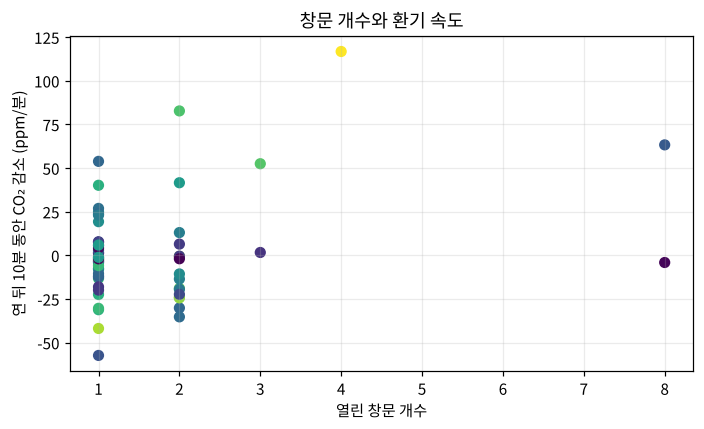

In [3]:
ev = []
opened = (c["win_n"] > 0) & (c["win_n"].shift(1) == 0)
for i in np.where(opened)[0]:
    if i + 10 >= len(c) or pd.isna(c["co2s"].iloc[i]) or pd.isna(c["co2s"].iloc[i + 10]): continue
    seg = c.iloc[i:i + 11]
    if (seg["time"].diff().dt.total_seconds().fillna(60) > 120).any(): continue
    ev.append({"시각": c["time"].iloc[i], "열린 창문": int(seg["win_n"].max()), "연 순간 CO₂": c["co2s"].iloc[i],
               "10분 뒤 CO₂": c["co2s"].iloc[i + 10], "감소(ppm/분)": (c["co2s"].iloc[i] - c["co2s"].iloc[i + 10]) / 10})
ev = pd.DataFrame(ev)
print(f"창문을 연 사건 {len(ev)}번")
if len(ev):
    ev = ev[ev["연 순간 CO₂"] > 900]
    print(ev.groupby(pd.cut(ev["열린 창문"], [0, 1, 2, 8], labels=["1개", "2개", "3개 이상"]), observed=True)
          .agg(사건=("감소(ppm/분)", "size"), 평균감소=("감소(ppm/분)", "mean"), 연순간CO2=("연 순간 CO₂", "mean")).round(1).to_string())
    fig, a = plt.subplots(figsize=(6.5, 4))
    a.scatter(ev["열린 창문"], ev["감소(ppm/분)"], c=ev["연 순간 CO₂"], cmap="viridis", s=40)
    a.set_xlabel("열린 창문 개수"); a.set_ylabel("연 뒤 10분 동안 CO₂ 감소 (ppm/분)"); a.set_title("창문 개수와 환기 속도"); a.grid(alpha=.25)
    plt.tight_layout(); plt.savefig(f"{RES}/04_window_ventilation.png", dpi=150); plt.show()
ev.to_csv(f"{RES}/04_window_events.csv", index=False, encoding="utf-8-sig")

## 3) 인공신경망 '최적' 확률 지도
03번에서 학습한 상태 분류 MLP에 CO₂ 평균과 10분 급증 횟수를 바꿔 넣고(나머지 특징은 측정 중앙값으로 고정) '최적'일 확률을 그린다.

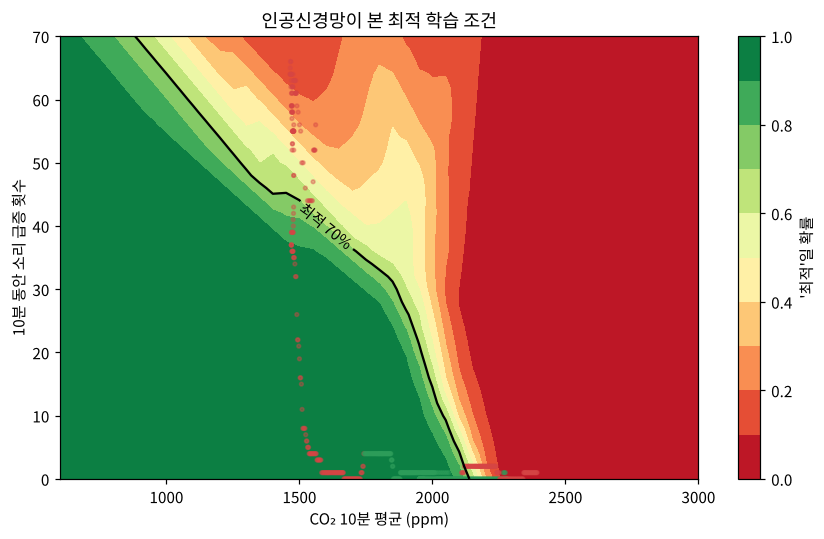

최적 확률 70% 이상: CO₂ 600~2100 ppm, 급증 0~70회/10분
(학습 데이터 범위: CO₂ 1465~2394 ppm — 범위 밖은 외삽이라 신뢰도 낮음)


In [4]:
try:
    pack = joblib.load(f"{PROC}/state_mlp8.joblib")
    lab = pd.read_csv(f"{PROC}/labeled.csv", encoding="utf-8-sig")
    m, sc, F = pack["model"], pack["scaler"], pack["feats"]
    base = lab[F].median()
    co2g = np.linspace(600, 3000, 49); spg = np.arange(0, 71, 2)
    G = np.array([[0.0] * len(co2g) for _ in spg])
    k0 = list(m.classes_).index(0)
    for i, s in enumerate(spg):
        Xg = pd.DataFrame([base.values] * len(co2g), columns=F)
        Xg["f_co2_mean"] = co2g; Xg["f_snd_spikes"] = s
        G[i] = m.predict_proba(sc.transform(Xg))[:, k0]
    fig, a = plt.subplots(figsize=(8, 5))
    im = a.contourf(co2g, spg, G, levels=np.linspace(0, 1, 11), cmap="RdYlGn")
    cs = a.contour(co2g, spg, G, levels=[.7], colors="black", linewidths=1.5); a.clabel(cs, fmt="최적 70%%")
    plt.colorbar(im, label="'최적'일 확률")
    a.scatter(lab["f_co2_mean"], lab["f_snd_spikes"], c=lab["state_label"].map(STATE_COLOR), s=6, alpha=.4, label="실제 기록")
    a.set_xlabel("CO₂ 10분 평균 (ppm)"); a.set_ylabel("10분 동안 소리 급증 횟수"); a.set_title("인공신경망이 본 최적 학습 조건")
    plt.tight_layout(); plt.savefig(f"{RES}/04_optimal_map.png", dpi=150); plt.show()
    ok = pd.DataFrame(G, index=spg, columns=co2g.round()).stack()
    ok = ok[ok >= .7].reset_index(); ok.columns = ["급증", "CO2", "p"]
    if len(ok): print(f"최적 확률 70% 이상: CO₂ {ok.CO2.min():.0f}~{ok.CO2.max():.0f} ppm, 급증 {ok['급증'].min()}~{ok['급증'].max()}회/10분")
    print(f"(학습 데이터 범위: CO₂ {lab.f_co2_mean.min():.0f}~{lab.f_co2_mean.max():.0f} ppm — 범위 밖은 외삽이라 신뢰도 낮음)")
except FileNotFoundError:
    print("03번을 먼저 실행하세요")